# Notebook 6. Giải vòng tròn cấp 1–7 và tổng hợp

Người phụ trách: Nguyễn Trọng Phúc.

Nội dung:
1. Giải vòng tròn 7 cấp, mỗi cặp `tournament.games_per_pair` ván, đổi bên đi trước sau mỗi ván, mỗi ván một seed.
2. Ma trận đối đầu, bảng thắng/hòa/thua, khoảng tin cậy Wilson 95%, xếp hạng.
3. Ảnh hưởng bên đi trước.
4. Chi phí: thời gian mỗi nước (TB, p95), số nút/mô phỏng, kích thước mô hình, thời gian huấn luyện, bộ nhớ.
5. Độ chính xác chiến thuật của cả 7 cấp.
6. Ván minh họa: một ván cấp mạnh hơn thua, một ván bình thường (lấy theo quy tắc cố định, không chọn tay).

Cấu hình mặc định của từng cấp lấy từ `config.yaml`. Mỗi ván mở đầu bằng 2 nước ngẫu nhiên có seed để các tác tử tất định (cấp 5, 6) không lặp lại một ván.
Cần có đủ mô hình trong `files/` (nb3, nb4, nb5) và `files/tactics.json` (nb2).

In [1]:
# QUICK = True: chạy thử vài ván, vài epoch để kiểm tra code (ghi vào thư mục con thu_nhanh/)
# QUICK = False: chạy thật theo config.yaml, kết quả dùng cho báo cáo
QUICK = False

import os
if not os.path.exists("config.yaml"):
    raise RuntimeError("Hãy mở Jupyter trong thư mục final_connect_four (nơi có config.yaml).")

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils.experiments import setup, summaries_table, with_random_opening, move_times_of
from utils.arena import run_match, format_summary, read_log, first_player_stats
from utils.data import machine_info
from utils.conn_simple_env import conn
from utils import tactics
from utils.arena import round_robin
from utils.experiments import plot_matrix, matrix_table, info_mean, records_of, LEVEL_LABELS
ex = setup(QUICK)
cfg = ex.cfg
print("Cấu hình máy:", machine_info())

Chế độ: chạy thật. Log: results/logs\ | Hình: results\figures\ | Mô hình: files\
Cấu hình máy: {'system': 'Windows', 'release': '11', 'processor': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel', 'cpu_count': 16, 'python': '3.13.5'}


## 1. Giải vòng tròn

In [2]:
tour_cfg = cfg["tournament"]
names = tour_cfg["agents"]
opening = tour_cfg["opening_random_moves"]
for name in names:
    if not ex.model_ready(name):
        raise RuntimeError(f"Thiếu mô hình cho {name}, chạy nb3, nb4, nb5 trước.")

agents = {}
for name in names:
    agents[name] = with_random_opening(ex.agent(name), opening)

n_games = ex.n(tour_cfg["games_per_pair"], 4)
log_path = ex.log("nb6_giai_dau.jsonl")
start = time.perf_counter()
summaries, matrix = round_robin(agents, n_games, seed=tour_cfg["seed"], log_path=log_path)
print("Giải đấu chạy mất", round(time.perf_counter() - start), "giây")

tour_table = summaries_table(summaries)
tour_table.to_csv(ex.table("nb6_giai_dau.csv"), index=False, encoding="utf-8-sig")
tour_table

Giải đấu chạy mất 5202 giây


,tác tử,đối thủ,số ván,thắng,hòa,thua,score,Wilson 95%,TB (ms),p95 (ms),xử thua
0,cap1,cap2,200,1,0,199,0.005,"[0.001, 0.028]",0.0,0.0,0
1,cap1,cap3,200,0,0,200,0.000,"[0.000, 0.019]",0.0,0.0,0
2,cap1,cap4,200,0,0,200,0.000,"[0.000, 0.019]",0.0,0.0,0
3,cap1,cap5,200,37,0,163,0.185,"[0.137, 0.245]",0.0,0.0,0
4,cap1,cap6,200,32,0,168,0.160,"[0.116, 0.217]",0.0,0.0,0
5,cap1,cap7,200,7,0,193,0.035,"[0.017, 0.070]",0.0,0.0,0
6,cap2,cap3,200,8,2,190,0.045,"[0.024, 0.083]",2.0,5.2,0
7,cap2,cap4,200,14,5,181,0.083,"[0.052, 0.129]",1.9,4.9,0
8,cap2,cap5,200,181,1,18,0.907,"[0.859, 0.940]",1.4,3.9,0
9,cap2,cap6,200,199,0,1,0.995,"[0.972, 0.999]",1.5,4.0,0


,Cấp 1,Cấp 2,Cấp 3,Cấp 4,Cấp 5,Cấp 6,Cấp 7
Cấp 1,NaN,0.005,0.000,0.000,0.185,0.160,0.035
Cấp 2,0.995,NaN,0.045,0.083,0.907,0.995,0.357
Cấp 3,1.000,0.955,NaN,0.670,0.838,1.000,0.632
Cấp 4,1.000,0.917,0.330,NaN,0.910,1.000,0.578
Cấp 5,0.815,0.093,0.162,0.090,NaN,0.845,0.122
Cấp 6,0.840,0.005,0.000,0.000,0.155,NaN,0.025
Cấp 7,0.965,0.643,0.368,0.422,0.877,0.975,NaN


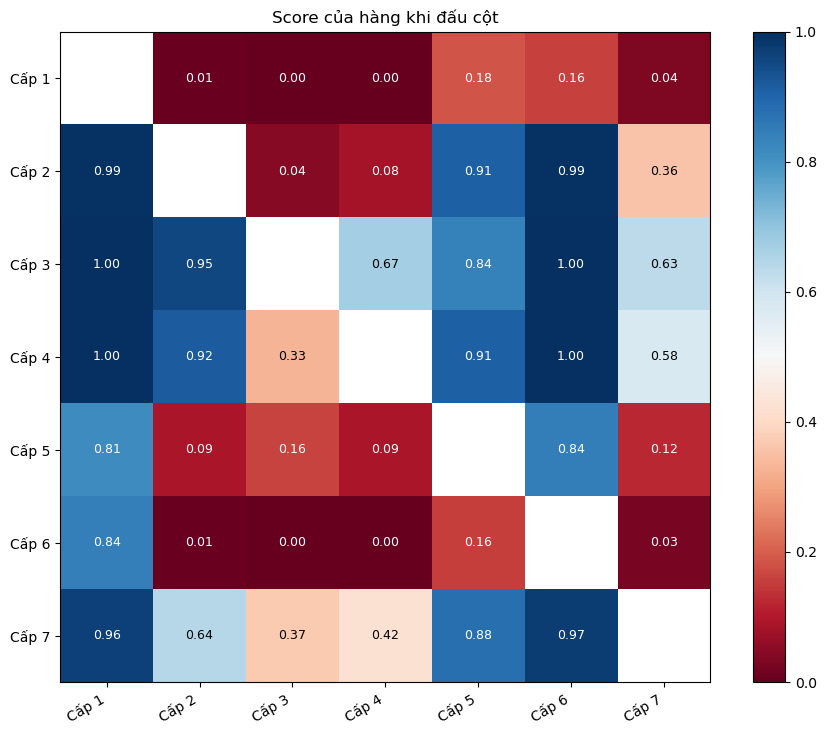

In [3]:
matrix_df = matrix_table(matrix, names)
matrix_df.to_csv(ex.table("nb6_ma_tran.csv"), encoding="utf-8-sig")
plot_matrix(matrix, names, ex.fig("nb6_ma_tran.png"))
matrix_df

In [4]:
# Xếp hạng theo score trung bình khi gặp 6 cấp còn lại
rows = []
for a in names:
    scores = []
    for b in names:
        if a != b:
            scores.append(matrix[a][b])
    rows.append({"tác tử": LEVEL_LABELS[a], "score TB": round(float(np.mean(scores)), 3)})
rank_table = pd.DataFrame(rows).sort_values("score TB", ascending=False).reset_index(drop=True)
rank_table.index = rank_table.index + 1
rank_table.to_csv(ex.table("nb6_xep_hang.csv"), encoding="utf-8-sig")
rank_table

,tác tử,score TB
1,Cấp 3,0.849
2,Cấp 4,0.789
3,Cấp 7,0.708
4,Cấp 2,0.564
5,Cấp 5,0.355
6,Cấp 6,0.171
7,Cấp 1,0.064


## 2. Ảnh hưởng bên đi trước

Connect Four 7×6 đã được giải: bên đi trước thắng nếu chơi hoàn hảo. Bảng dưới cho tỷ lệ chung và score của mỗi tác tử khi cầm đỏ so với khi cầm vàng.

In [5]:
records = read_log(log_path)
print("Toàn giải:", first_player_stats(records))

rows = []
for a in names:
    as_red = []
    as_yellow = []
    for s in summaries:
        if s["agent"] == a:
            as_red.append(s["score_as_red"])
            as_yellow.append(s["score_as_yellow"])
        if s["opponent"] == a:
            # thống kê lưu theo góc agent nên đổi sang góc của a
            as_red.append(1 - s["score_as_yellow"])
            as_yellow.append(1 - s["score_as_red"])
    rows.append({"tác tử": LEVEL_LABELS[a], "score TB khi cầm đỏ": round(float(np.mean(as_red)), 3),
                 "score TB khi cầm vàng": round(float(np.mean(as_yellow)), 3)})
first_table = pd.DataFrame(rows)
first_table.to_csv(ex.table("nb6_ben_di_truoc.csv"), index=False, encoding="utf-8-sig")
first_table

Toàn giải: {'games': 4200, 'red_win_rate': 0.5159523809523809, 'draw_rate': 0.02023809523809524, 'yellow_win_rate': 0.4638095238095238}


,tác tử,score TB khi cầm đỏ,score TB khi cầm vàng
0,Cấp 1,0.078,0.050
1,Cấp 2,0.589,0.538
2,Cấp 3,0.884,0.814
3,Cấp 4,0.813,0.765
4,Cấp 5,0.374,0.335
5,Cấp 6,0.183,0.158
6,Cấp 7,0.760,0.657


## 3. Chi phí tính toán

Thời gian mỗi nước tính trên mọi ván của giải, bỏ 2 nước khai cuộc ngẫu nhiên. Cấp 3 ghi số nút, cấp 4 và 7 ghi số mô phỏng.

In [6]:
def all_records_of(agent_name):
    result = []
    for r in records:
        if r["red"] == agent_name or r["yellow"] == agent_name:
            result.append(r)
    return result

def file_size_mb(path):
    if os.path.exists(path):
        return round(os.path.getsize(path) / 1e6, 2)
    return None

def train_seconds(path):
    meta_path = path + ".json"
    if not os.path.exists(meta_path):
        return None
    with open(meta_path, encoding="utf-8") as f:
        meta = json.load(f)
    report = meta.get("report", {})
    if "train_seconds" in report:
        return report["train_seconds"]
    total = 0
    for stage in ["stage1", "stage2"]:
        if stage in report:
            total += report[stage]["seconds"]
    return total

model_files = {
    "cap5": [ex.model("policy_conn.keras")],
    "cap6": [ex.model("pg_conn.keras")],
    "cap7": [ex.model("policy_conn.keras"), ex.model("value_conn.keras")],
}

rows = []
for name in names:
    agent_records = all_records_of(name)
    mean_t, p95_t = move_times_of(agent_records, name)
    row = {"tác tử": LEVEL_LABELS[name], "TB (ms)": round(mean_t * 1000, 1), "p95 (ms)": round(p95_t * 1000, 1),
           "số nút TB": info_mean(agent_records, name, "nodes"),
           "số mô phỏng TB": info_mean(agent_records, name, "simulations")}
    if name in model_files:
        sizes = [file_size_mb(p) for p in model_files[name]]
        row["mô hình (MB)"] = sum(x for x in sizes if x is not None)
        row["huấn luyện (giây)"] = sum(train_seconds(p) or 0 for p in model_files[name])
    rows.append(row)
cost_table = pd.DataFrame(rows)
cost_table.to_csv(ex.table("nb6_chi_phi.csv"), index=False, encoding="utf-8-sig")
cost_table

,tác tử,TB (ms),p95 (ms),số nút TB,số mô phỏng TB,mô hình (MB),huấn luyện (giây)
0,Cấp 1,0.0,0.0,NaN,NaN,NaN,NaN
1,Cấp 2,2.0,4.5,NaN,NaN,NaN,NaN
2,Cấp 3,37.3,80.7,490.300945,NaN,NaN,NaN
3,Cấp 4,47.2,97.7,NaN,396.350157,NaN,NaN
4,Cấp 5,1.4,2.3,NaN,NaN,4.24,40.6
5,Cấp 6,1.8,3.0,NaN,NaN,5.66,951.3
6,Cấp 7,360.0,707.8,NaN,196.570057,8.48,88.8


In [7]:
# Bộ nhớ của tiến trình notebook sau khi đã nạp đủ 7 tác tử (cần thư viện psutil)
try:
    import psutil
    rss = psutil.Process(os.getpid()).memory_info().rss / 1e6
    print(f"RAM tiến trình: {rss:.0f} MB")
except ImportError:
    print("Chưa cài psutil (pip install psutil) nên không đo được RAM.")

RAM tiến trình: 546 MB


## 4. Độ chính xác chiến thuật của 7 cấp

In [8]:
positions = tactics.load_tactics(ex.model("tactics.json"))
rows = []
for name in names:
    move_fn, info_fn = ex.agent(name)
    row = {"tác tử": LEVEL_LABELS[name]}
    row.update(tactics.score_agent(move_fn, positions))
    rows.append(row)
tactics_table = pd.DataFrame(rows).round(3)
tactics_table.to_csv(ex.table("nb6_chien_thuat.csv"), index=False, encoding="utf-8-sig")
tactics_table

,tác tử,win_now,must_block,double_threat,all
0,Cấp 1,0.214,0.154,0.385,0.250
1,Cấp 2,1.000,1.000,1.000,1.000
2,Cấp 3,1.000,1.000,1.000,1.000
3,Cấp 4,1.000,1.000,1.000,1.000
4,Cấp 5,0.143,0.462,0.308,0.300
5,Cấp 6,0.214,0.231,0.000,0.150
6,Cấp 7,1.000,0.846,0.462,0.775


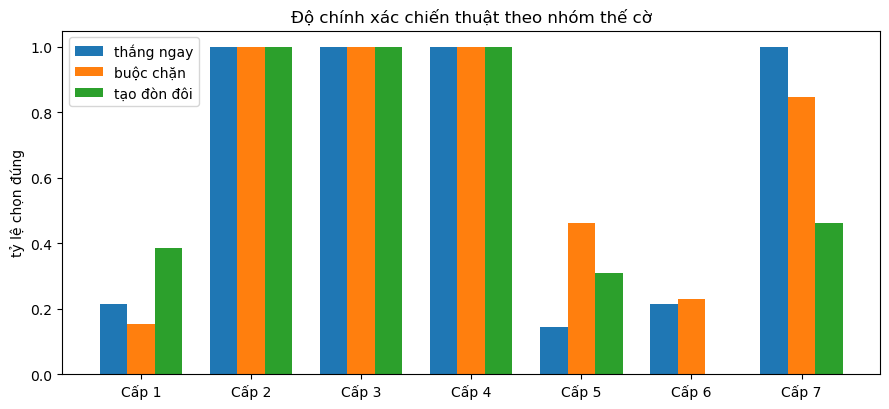

In [9]:
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(9, 4.2))
width = 0.25
for offset, group, label in [(-width, "win_now", "thắng ngay"), (0, "must_block", "buộc chặn"),
                             (width, "double_threat", "tạo đòn đôi")]:
    ax.bar(x + offset, tactics_table[group], width=width, label=label)
ax.set_xticks(x, [LEVEL_LABELS[n] for n in names])
ax.set_ylim(0, 1.05)
ax.set_ylabel("tỷ lệ chọn đúng")
ax.set_title("Độ chính xác chiến thuật theo nhóm thế cờ")
ax.legend()
fig.tight_layout()
fig.savefig(ex.fig("nb6_chien_thuat.png"), dpi=150)

## 5. Ván minh họa

Quy tắc chọn cố định để tránh chọn riêng ván đẹp:
- ván đầu tiên trong log mà cấp có score trung bình cao nhất bị thua;
- ván đầu tiên trong log giữa hai cấp đứng đầu bảng xếp hạng.

In [10]:
code_by_label = {}
for name in names:
    code_by_label[LEVEL_LABELS[name]] = name
top = code_by_label[rank_table.iloc[0]["tác tử"]]
second = code_by_label[rank_table.iloc[1]["tác tử"]]

def show_game(record, title):
    env = conn.from_moves(record["moves"])
    print(title)
    print(f"Đỏ: {record['red']}, vàng: {record['yellow']}, người thắng: {record['winner']}, số nước: {len(record['moves'])}")
    print("Các nước:", record["moves"])
    print(env.render())
    print()

loss_game = None
for r in records:
    loser_is_top = (r["winner"] == "red" and r["yellow"] == top) or (r["winner"] == "yellow" and r["red"] == top)
    if loser_is_top:
        loss_game = r
        break
if loss_game is None:
    print(LEVEL_LABELS[top], "không thua ván nào trong giải.")
else:
    show_game(loss_game, f"Ván {LEVEL_LABELS[top]} thua:")

for r in records:
    if set([r["red"], r["yellow"]]) == set([top, second]):
        show_game(r, f"Ván giữa hai cấp đứng đầu ({LEVEL_LABELS[top]} và {LEVEL_LABELS[second]}):")
        break

Ván Cấp 3 thua:
Đỏ: cap3, vàng: cap2, người thắng: yellow, số nước: 36
Các nước: [3, 4, 4, 3, 3, 6, 4, 5, 7, 3, 4, 4, 4, 6, 6, 3, 6, 2, 2, 1, 2, 3, 1, 1, 2, 2, 6, 6, 2, 7, 7, 7, 7, 7, 1, 1]
. X O X . O O
O O O O . X X
X X O X . X O
O X X X . X X
X X O X . O O
O O X O O O X
1 2 3 4 5 6 7

Ván giữa hai cấp đứng đầu (Cấp 3 và Cấp 4):
Đỏ: cap3, vàng: cap4, người thắng: yellow, số nước: 32
Các nước: [7, 4, 4, 3, 2, 5, 6, 5, 4, 5, 5, 3, 3, 5, 3, 4, 3, 3, 4, 7, 4, 1, 5, 1, 1, 1, 1, 1, 7, 7, 6, 6]
O . O X X . .
X . X X O . .
O . X O X . O
X . X X O O X
O . O X O X O
O X O O O X X
1 2 3 4 5 6 7



In [11]:
# Thế cờ chiến thuật mà cấp đứng đầu chọn sai (nếu có)
move_fn, info_fn = ex.agent(top)
wrong = 0
for i, pos in enumerate(positions):
    import random
    random.seed(i)
    np.random.seed(i)
    env = conn.from_moves(pos["moves"])
    move = move_fn(env.clone())
    if move not in pos["answers"]:
        wrong += 1
        if wrong <= 3:
            print(f"{pos['id']}: {LEVEL_LABELS[top]} đi cột {move}, đáp án {pos['answers']}")
            print(env.render())
            print()
print("Tổng số thế chọn sai:", wrong, "/", len(positions))

Tổng số thế chọn sai: 0 / 40
